In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [33]:
combine_tracking = pd.read_csv("data/combine_tracking.csv")
combine_results = pd.read_csv("data/combine_results.csv")

# What Does This Data Set Contain?

There are 14 columns listed. They are:
- `draft_year`
    - Year of the combine testing
- `event_id`
    - Unique identifier linking all tracking frames within a single continuous drill attempt
- `nfl_id`
    - Player identifier 
- `entity_type`
    - Entity tracked, either ball or player
- `time`
    - Time stamp for every frame of a drill, tracked ever 0.10 seconds
- `drill_type`
    - Drill category
- `drill_name`
    - Specific drill name
- `attempt`
    - Attempt number
- `x`
    - Player horizontal position 
- `y`
    - Player vertical position
- `s`
    - Player speed in yds/s
- `a`
    - Player acceleration in yds/s^2
- `dis`
    - Distance traveled by player from previous tracking frame in yards
- `dir`
    - Player motion direction angle in degrees

In [2]:
oline = combine_tracking[combine_tracking['drill_type'] == 'SKILL_DRILLS_OL']

This data set contains 121 athletes from three seasons

Each of these rows correlates to a specific player and the specific type of OL drill they ran.

The drills are:
- OL_PULL_DRILL_FOLD_BLOCK_RIGHT
- OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT
- OL_PULL_DRILL_LONG_PULL_RIGHT
- PASS_RUSH_DROP
- SCREEN_DRILL
- PASS_PRO-MIRROR_DRILL
- FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE
- PASS_PRO_MIRROR_DRILL

In [7]:
oline['nfl_id'].unique()

array([58286, 58896, 58261, 58454, 58259, 58866, 58300, 58226, 58994,
       58231, 58416, 58211, 58209, 58359, 58242, 58296, 58898, 58253,
       58220, 58940, 58852, 58423, 58958, 58332, 58294, 58373, 58214,
       58206, 58346, 58396, 58303, 58376, 58476, 58987, 58455, 58358,
       58262, 58946, 57184, 57863, 57444, 57299, 57428, 57628, 57283,
       57581, 57376, 57240, 57262, 57194, 57135, 57238, 57183, 57297,
       57330, 57189, 57150, 57353, 57357, 57293, 57599, 57224, 57126,
       57687, 57141, 57854, 57207, 57335, 57172, 57176, 57408, 57654,
       57202, 57284, 57180, 57337, 57374, 57796, 57128, 57198, 57406,
       57165, 57368, 57310, 55891, 56183, 56034, 55924, 56066, 55901,
       56344, 55962, 55983, 56518, 55922, 56636, 55870, 56645, 55987,
       55903, 55913, 56095, 56103, 55973, 55878, 56572, 55971, 55930,
       55927, 56451, 56055, 55982, 55875, 56203, 55874, 56021, 56450,
       55968, 55976, 56090, 56625])

In [93]:
wright = oline[oline['nfl_id'] == 55874]

In [20]:
wright.groupby(['drill_name', 'attempt']).size().reset_index(name='count')

,drill_name,attempt,count
0,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,1,142
1,OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,1,55
2,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,1,37
3,OL_PULL_DRILL_LONG_PULL_RIGHT,1,51
4,PASS_PRO_MIRROR_DRILL,1,161
5,PASS_RUSH_DROP,1,42
6,PASS_RUSH_DROP,2,44
7,SCREEN_DRILL,1,65


# Isolating how Darnell Wright did on his drills

For this section we will focus on offensive tackle Darnell Wright and how he performed in his drills

The first focus is on his pass rush drop drill for attempt one

In [31]:
pass_rush_drop = wright.loc[
    (wright['drill_name'] == 'PASS_RUSH_DROP') &
    (wright['attempt'] == 1),
    ['x', 'y', 'a', 'time']
].rename(columns = {'a': 'acceleration'})

# Convert time to datetime
pass_rush_drop['time'] = pd.to_datetime(pass_rush_drop['time'])

# Calculate elapsed time
pass_rush_drop['time'] = (
    pass_rush_drop['time'] - pass_rush_drop['time'].min()
).dt.total_seconds()

In [ ]:
weight = combine_results.loc[
    combine_results['nfl_id'] == 55874,
    'combine_weight'
].iloc[0]

np.int64(999)

In [61]:
pass_rush_drop['force'] = (
    pass_rush_drop['acceleration'] * (weight / 2.20462)
).round(2)

## Force over Time

During the drill we can measure the exact force in Newtons that Wright is exerting on every given tenth of a second.

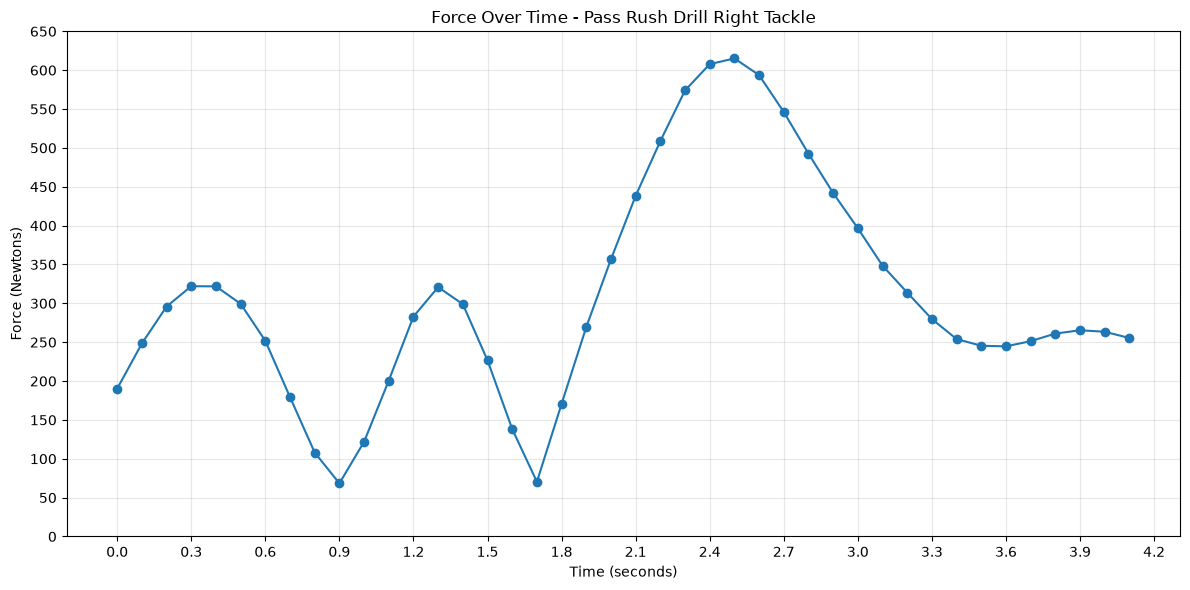

In [102]:
plt.figure(figsize=(12, 6))

plt.plot(
    pass_rush_drop['time'],
    pass_rush_drop['force'],
    marker='o',
    linestyle='-'
)

plt.xlabel('Time (seconds)')
plt.ylabel('Force (Newtons)')
plt.title('Force Over Time - Pass Rush Drill Right Tackle')

plt.yticks(range(0, 651, 50))
plt.xticks(np.arange(0, 4.21, 0.3))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

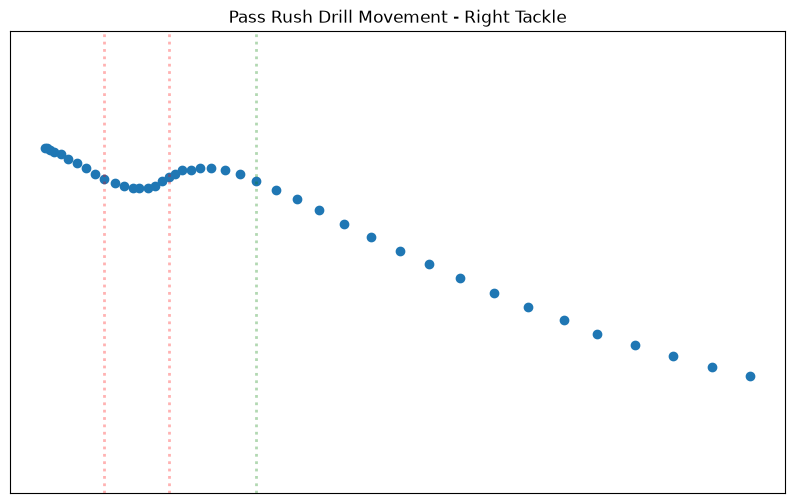

In [117]:
plt.figure(figsize=(10, 6))
plt.scatter(pass_rush_drop['x'], pass_rush_drop['y'])


plt.axvline(x = 44, color = 'red', linestyle = ':', linewidth = 2, alpha = 0.3)
plt.axvline(x = 43.033333, color = 'red', linestyle = ':', linewidth = 2, alpha = 0.3)
plt.axvline(x = 41.733333, color = 'green', linestyle = ':', linewidth = 2, alpha = 0.3)

plt.xticks([])
plt.yticks([])

plt.title('Pass Rush Drill Movement - Right Tackle')

plt.axis('equal')
plt.gca().invert_xaxis()
plt.show()

In [109]:
pass_rush_drop

,x,y,acceleration,time,force
351773,44.866667,26.933333,1.259652,0.0,190.27
351774,44.833333,26.933333,1.644553,0.1,248.40
351775,44.800000,26.900000,1.959164,0.2,295.92
351776,44.733333,26.866667,2.132135,0.3,322.05
351777,44.633333,26.833333,2.130748,0.4,321.84
351778,44.533333,26.766667,1.982022,0.5,299.38
351779,44.400000,26.700000,1.666617,0.6,251.74
351780,44.266667,26.633333,1.186615,0.7,179.23
351781,44.133333,26.533333,0.714804,0.8,107.97
351782,44.000000,26.466667,0.452904,0.9,68.41
